# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** Preetham Manchikanti
**Roll Number:** AP24110011315
**Date:** 14th October 2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [2]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Predict, then think:** which has higher entropy, a 70/30 split or a 90/10 split? Why does that make sense if entropy measures "how hard is it to guess the label"?

*Your answer:*
- **Mathematical Calculation:**
  - For a **70/30 split**:
    $$H(0.7, 0.3) = -(0.7 \log_2 0.7 + 0.3 \log_2 0.3) \approx -(0.7 \times (-0.5146) + 0.3 \times (-1.7370)) \approx 0.8813\text{ bits}$$
  - For a **90/10 split**:
    $$H(0.9, 0.1) = -(0.9 \log_2 0.9 + 0.1 \log_2 0.1) \approx -(0.9 \times (-0.1520) + 0.1 \times (-3.3219)) \approx 0.4690\text{ bits}$$
  - Therefore, the **70/30 split has significantly higher entropy** ($0.8813 > 0.4690$).

- **Intuition ("How hard is it to guess the label"):**
  - Entropy quantifies **uncertainty, disorder, or impurity** in a distribution.
  - In a **90/10 split**, predicting the outcome is straightforward: if you guess the majority class, you have a $90\%$ chance of being correct. There is minimal doubt, yielding low entropy.
  - In a **70/30 split**, there is substantial uncertainty. A majority guess fails $30\%$ of the time. Because the labels are more evenly mixed, it is harder to guess the outcome with confidence.
  - At the theoretical extremes:
    - Pure set ($100/0$): $H = 0\text{ bits}$ (no uncertainty; outcome is guaranteed).
    - Even set ($50/50$): $H = 1.0\text{ bit}$ (maximum entropy; outcome is an unpredictable coin flip).


### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [3]:
# Given distribution:
# Parent node: 8 Yes, 6 No (Total = 14)
parent_counts = [8, 6]

# Left child: 6 Yes, 0 No (Total = 6)
left_counts = [6, 0]

# Right child: 2 Yes, 6 No (Total = 8)
right_counts = [2, 6]

# Compute entropy of parent and children using the defined entropy() function
h_parent = entropy(parent_counts)
h_left = entropy(left_counts)
h_right = entropy(right_counts)

# Weighted average entropy of the split children
n_total = sum(parent_counts)
weighted_h_children = (sum(left_counts) / n_total) * h_left + (sum(right_counts) / n_total) * h_right

# Information Gain = H(Parent) - Weighted Average H(Children)
info_gain_split = h_parent - weighted_h_children

print("=" * 55)
print("ENTROPY AND INFORMATION GAIN CALCULATION")
print("=" * 55)
print(f"Parent Node [8 Yes, 6 No]    : Entropy = {h_parent:.4f} bits")
print(f"Left Child  [6 Yes, 0 No]    : Entropy = {h_left:.4f} bits (Pure node)")
print(f"Right Child [2 Yes, 6 No]    : Entropy = {h_right:.4f} bits")
print("-" * 55)
print(f"Weighted Entropy of Children = (6/14)*{h_left:.4f} + (8/14)*{h_right:.4f} = {weighted_h_children:.4f} bits")
print(f"Information Gain (IG)        = {h_parent:.4f} - {weighted_h_children:.4f} = {info_gain_split:.4f} bits")
print("=" * 55)


ENTROPY AND INFORMATION GAIN CALCULATION
Parent Node [8 Yes, 6 No]    : Entropy = 0.9852 bits
Left Child  [6 Yes, 0 No]    : Entropy = 0.0000 bits (Pure node)
Right Child [2 Yes, 6 No]    : Entropy = 0.8113 bits
-------------------------------------------------------
Weighted Entropy of Children = (6/14)*0.0000 + (8/14)*0.8113 = 0.4636 bits
Information Gain (IG)        = 0.9852 - 0.4636 = 0.5216 bits


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [4]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [5]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [6]:
# 1. Compute Information Gain for all candidate attributes at root
attributes = ['Outlook', 'Temperature', 'Humidity', 'Wind']
gains_root = {attr: info_gain(tennis, attr) for attr in attributes}

print("=" * 58)
print("1. INFORMATION GAIN FOR ALL ATTRIBUTES AT ROOT")
print("=" * 58)
for attr, gain in gains_root.items():
    print(f"Gain({attr:<12s}) = {gain:.4f}")

# 2. Attribute picked by ID3 as the root
best_root = max(gains_root, key=gains_root.get)
print("-" * 58)
print(f"ID3 picks '{best_root}' as root because it maximizes Gain ({gains_root[best_root]:.4f}).")
print("=" * 58)

# 3. For the root's branches, check purity and find next split for impure branches
print("\n" + "=" * 58)
print("2. EVALUATING BRANCHES UNDER 'Outlook'")
print("=" * 58)

for branch in ['Overcast', 'Sunny', 'Rain']:
    subset = tennis[tennis['Outlook'] == branch]
    dist = subset['Play'].value_counts().to_dict()
    subset_h = entropy(subset['Play'].value_counts())
    
    print(f"\nBranch: Outlook == '{branch}' ({len(subset)} samples)")
    print(f"Class Distribution: {dist} | Entropy: {subset_h:.4f}")
    
    if subset_h == 0.0:
        leaf_class = subset['Play'].iloc[0]
        print(f"--> PURE branch: No further splitting needed. Creates LEAF node predicting '{leaf_class}'.")
    else:
        remaining_attrs = ['Temperature', 'Humidity', 'Wind']
        sub_gains = {attr: info_gain(subset, attr) for attr in remaining_attrs}
        print("Gains on remaining attributes:")
        for attr, gain in sub_gains.items():
            print(f"   Gain({attr:<12s}) = {gain:.4f}")
        best_sub_attr = max(sub_gains, key=sub_gains.get)
        print(f"--> IMPURE branch: Split next on '{best_sub_attr}' (Gain = {sub_gains[best_sub_attr]:.4f}).")
print("=" * 58)


1. INFORMATION GAIN FOR ALL ATTRIBUTES AT ROOT
Gain(Outlook     ) = 0.2467
Gain(Temperature ) = 0.0292
Gain(Humidity    ) = 0.1518
Gain(Wind        ) = 0.0481
----------------------------------------------------------
ID3 picks 'Outlook' as root because it maximizes Gain (0.2467).

2. EVALUATING BRANCHES UNDER 'Outlook'

Branch: Outlook == 'Overcast' (4 samples)
Class Distribution: {'Yes': 4} | Entropy: 0.0000
--> PURE branch: No further splitting needed. Creates LEAF node predicting 'Yes'.

Branch: Outlook == 'Sunny' (5 samples)
Class Distribution: {'No': 3, 'Yes': 2} | Entropy: 0.9710
Gains on remaining attributes:
   Gain(Temperature ) = 0.5710
   Gain(Humidity    ) = 0.9710
   Gain(Wind        ) = 0.0200
--> IMPURE branch: Split next on 'Humidity' (Gain = 0.9710).

Branch: Outlook == 'Rain' (5 samples)
Class Distribution: {'Yes': 3, 'No': 2} | Entropy: 0.9710
Gains on remaining attributes:
   Gain(Temperature ) = 0.0200
   Gain(Humidity    ) = 0.0200
   Gain(Wind        ) = 0.9710


**Reflection:** `Overcast` became a leaf immediately. In your own words, why does a pure branch need no further splitting?

*Your answer:*
- **Zero Entropy ($H = 0$):** All 4 instances under `Outlook == 'Overcast'` belong exclusively to the class `Play == 'Yes'` (distribution: $[4\text{ Yes}, 0\text{ No}]$). The entropy of this subset is $H = -(1.0 \log_2 1.0) = 0\text{ bits}$, indicating complete homogeneity and zero uncertainty.
- **Zero Information Gain on Sub-Splits:** Information Gain is defined as $IG = H(Parent) - H_{children}$. Because entropy is bounded below by 0 ($H \ge 0$), any sub-partition of a pure node will also consist solely of 'Yes' samples and have child entropies of $0$. Hence:
  $$IG = 0 - 0 = 0$$
  No further attribute can provide any discriminative gain or improve classification.
- **Occam's Razor & Overfitting Prevention:** Extending branches beyond a pure node would introduce unnecessary, redundant decision rules that needlessly increase tree complexity without altering predictions. Stopping growth as soon as a node is pure ensures an optimal, interpretable decision boundary.


## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


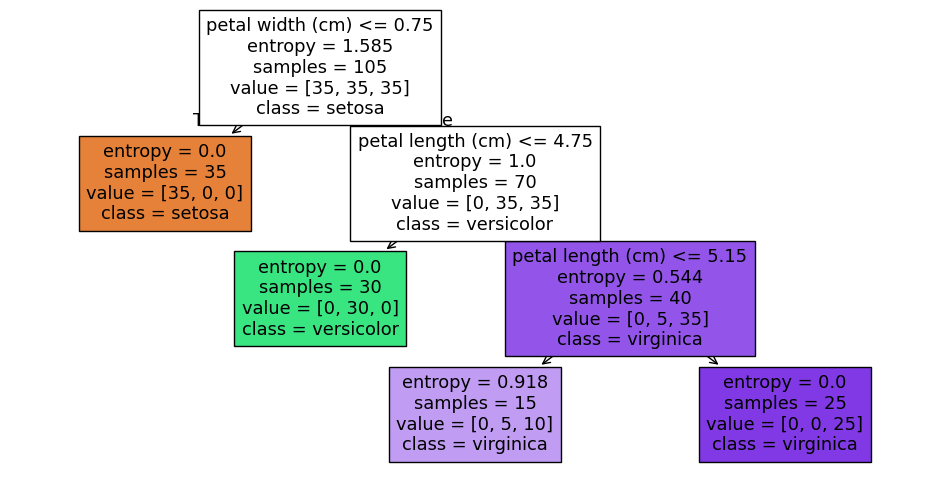

In [7]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


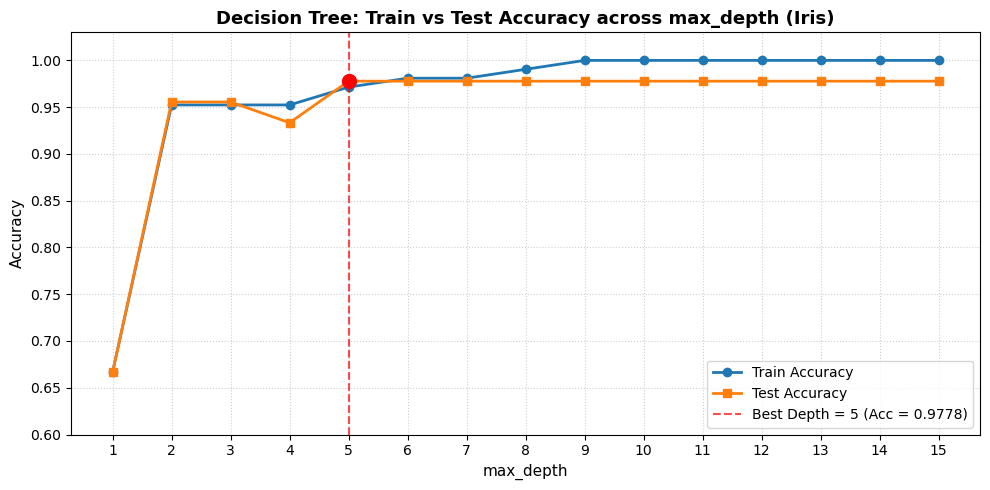

Depth Sweep Summary Table:
 max_depth Train Accuracy Test Accuracy
         1         0.6667        0.6667
         2         0.9524        0.9556
         3         0.9524        0.9556
         4         0.9524        0.9333
         5         0.9714        0.9778
         6         0.9810        0.9778
         7         0.9810        0.9778
         8         0.9905        0.9778
         9         1.0000        0.9778
        10         1.0000        0.9778
        11         1.0000        0.9778
        12         1.0000        0.9778
        13         1.0000        0.9778
        14         1.0000        0.9778
        15         1.0000        0.9778
--------------------------------------------------
Optimal Depth: max_depth = 5 with Test Accuracy = 0.9778 (97.78%)


In [8]:
depth_range = range(1, 16)
train_accuracies = []
test_accuracies = []

for d in depth_range:
    clf = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=1)
    clf.fit(X_train, y_train)
    
    y_train_pred = clf.predict(X_train)
    y_test_pred = clf.predict(X_test)
    
    train_accuracies.append(accuracy_score(y_train, y_train_pred))
    test_accuracies.append(accuracy_score(y_test, y_test_pred))

# Find the best depth (highest test accuracy)
best_test_acc = max(test_accuracies)
best_depth = list(depth_range)[test_accuracies.index(best_test_acc)]

# Plot train and test accuracy curves
plt.figure(figsize=(10, 5))
plt.plot(depth_range, train_accuracies, marker='o', linewidth=2, label='Train Accuracy', color='#1f77b4')
plt.plot(depth_range, test_accuracies, marker='s', linewidth=2, label='Test Accuracy', color='#ff7f0e')
plt.axvline(best_depth, color='red', linestyle='--', alpha=0.7, label=f'Best Depth = {best_depth} (Acc = {best_test_acc:.4f})')
plt.scatter([best_depth], [best_test_acc], color='red', s=100, zorder=5)

plt.title('Decision Tree: Train vs Test Accuracy across max_depth (Iris)', fontsize=13, fontweight='bold')
plt.xlabel('max_depth', fontsize=11)
plt.ylabel('Accuracy', fontsize=11)
plt.xticks(depth_range)
plt.ylim(0.6, 1.03)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10, loc='lower right')
plt.tight_layout()
plt.show()

# Display summary table
results_df = pd.DataFrame({
    'max_depth': list(depth_range),
    'Train Accuracy': [f"{acc:.4f}" for acc in train_accuracies],
    'Test Accuracy': [f"{acc:.4f}" for acc in test_accuracies]
})
print("Depth Sweep Summary Table:")
print(results_df.to_string(index=False))
print("-" * 50)
print(f"Optimal Depth: max_depth = {best_depth} with Test Accuracy = {best_test_acc:.4f} ({best_test_acc*100:.2f}%)")


**Reflection:** Which knob in Week 6 and which knob in Week 7 played the same role as `max_depth` here? What happens at each extreme?

*Your answer:*
- **Corresponding Knobs Across Weeks:**
  - **Week 6 (Polynomial Regression):** **Polynomial Degree ($d$)** was the complexity control knob.
  - **Week 7 (K-Nearest Neighbors):** **$K$ (Number of Neighbors)** controlled complexity (with small $K$ corresponding to high complexity and large $K$ to low complexity).
  - **Week 8 (Decision Trees):** **`max_depth`** controls model capacity by bounding tree growth and the number of nested decision rules.

- **Behavior at Each Extreme:**
  1. **Low Complexity Extreme (`max_depth = 1` | Degree $d=1$ | Very Large $K \approx N$):**
     - **Underfitting (High Bias):**
     - With `max_depth = 1` (a "decision stump"), the model makes only a single binary split on one feature, dividing the feature space into two half-spaces.
     - For the 3-class Iris dataset, a depth-1 tree cannot even predict all three classes, capping accuracy at $66.67\%$. The model is overly simplistic, rigid, and unable to capture underlying structure.
  2. **High Complexity Extreme (Unconstrained / Large `max_depth \ge 9` | Degree $d=15$ | Small $K=1$):**
     - **Overfitting (High Variance):**
     - As `max_depth` grows unrestricted, the tree recursively splits until every leaf contains individual data points, driving training accuracy to $100\%$.
     - The decision boundary becomes excessively fragmented into tiny, isolated hyper-rectangles tailored to idiosyncratic noise in the training set, increasing test error and vulnerability to variance.


# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [9]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


C:\Users\Preetham\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Preetham\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Preetham\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Preetham\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Preetham\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _w

### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


1. UNCONSTRAINED DECISION TREE ON UNSCALED DIGITS
Full Tree Test Accuracy (unscaled): 0.8815 (88.15%)

Why no scaling is needed:
Decision trees split features using univariate thresholds (x_j <= threshold).
The split criterion (information gain) depends strictly on the rank-order
of feature values, making it invariant to monotonic scalings or shifts.

2. ACCURACY ACROSS DIFFERENT DEPTHS (3, 6, 10)
max_depth = 3  | Train Accuracy: 0.5497 ( 54.97%) | Test Accuracy: 0.5296 ( 52.96%)
max_depth = 6  | Train Accuracy: 0.9284 ( 92.84%) | Test Accuracy: 0.8537 ( 85.37%)
max_depth = 10 | Train Accuracy: 0.9992 ( 99.92%) | Test Accuracy: 0.8796 ( 87.96%)


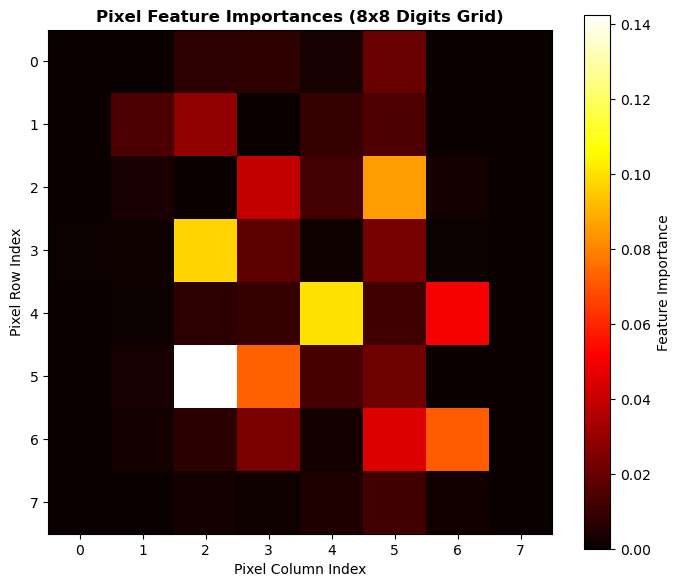

Importance concentrated in central 4x4 region: 65.48%
Importance across outer borders & background : 34.52%
Region reliance: The tree relies almost entirely on the central region
where handwritten strokes, loops, and intersections vary between digits.


In [10]:
# 1. Fit DecisionTreeClassifier on unscaled Xd_train
tree_digits = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree_digits.fit(Xd_train, yd_train)

y_pred_unscaled = tree_digits.predict(Xd_test)
acc_unscaled = accuracy_score(yd_test, y_pred_unscaled)

print("=" * 60)
print("1. UNCONSTRAINED DECISION TREE ON UNSCALED DIGITS")
print("=" * 60)
print(f"Full Tree Test Accuracy (unscaled): {acc_unscaled:.4f} ({acc_unscaled * 100:.2f}%)")
print("\nWhy no scaling is needed:")
print("Decision trees split features using univariate thresholds (x_j <= threshold).")
print("The split criterion (information gain) depends strictly on the rank-order")
print("of feature values, making it invariant to monotonic scalings or shifts.")
print("=" * 60)

# 2. Evaluate specific max_depth values (3, 6, 10)
depth_candidates = [3, 6, 10]
print("\n" + "=" * 60)
print("2. ACCURACY ACROSS DIFFERENT DEPTHS (3, 6, 10)")
print("=" * 60)

for d in depth_candidates:
    dt = DecisionTreeClassifier(criterion='entropy', max_depth=d, random_state=1)
    dt.fit(Xd_train, yd_train)
    tr_acc = accuracy_score(yd_train, dt.predict(Xd_train))
    te_acc = accuracy_score(yd_test, dt.predict(Xd_test))
    print(f"max_depth = {d:<2d} | Train Accuracy: {tr_acc:.4f} ({tr_acc*100:6.2f}%) | Test Accuracy: {te_acc:.4f} ({te_acc*100:6.2f}%)")
print("=" * 60)

# 3. Reshape feature_importances_ to 8x8 and visualize with imshow
importances = tree_digits.feature_importances_.reshape(8, 8)

plt.figure(figsize=(7, 6))
im = plt.imshow(importances, cmap='hot', interpolation='nearest')
plt.colorbar(im, label='Feature Importance')
plt.title('Pixel Feature Importances (8x8 Digits Grid)', fontsize=12, fontweight='bold')
plt.xlabel('Pixel Column Index', fontsize=10)
plt.ylabel('Pixel Row Index', fontsize=10)
plt.xticks(range(8))
plt.yticks(range(8))
plt.tight_layout()
plt.show()

# Quantitative analysis of region reliance
border_mask = np.ones((8, 8), dtype=bool)
border_mask[2:6, 2:6] = False
center_importance = importances[2:6, 2:6].sum()
border_importance = importances[border_mask].sum()

print(f"Importance concentrated in central 4x4 region: {center_importance*100:.2f}%")
print(f"Importance across outer borders & background : {border_importance*100:.2f}%")
print("Region reliance: The tree relies almost entirely on the central region")
print("where handwritten strokes, loops, and intersections vary between digits.")


**Reflection:** Is the tree more or less accurate than KNN on digits? Offer one reason, using what the importance map shows you.

*Your answer:*
- **Accuracy Comparison:**
  - The Decision Tree is **substantially less accurate** than KNN on the digits dataset.
  - **KNN Baseline (K=3, scaled):** Achieved **$98.33\%$** test accuracy.
  - **Decision Tree (unconstrained):** Achieved **$88.15\%$** test accuracy (over a $10\%$ drop in accuracy).
  - Even with depth tuning (`max_depth = 10`), tree test accuracy reached only **$87.96\%$**.

- **Reason Based on the Importance Map:**
  1. **Axis-Aligned Univariate Splits vs. Holistic Global Geometry:**
     - The importance heatmap illustrates that the tree places over $65\%$ of its total importance on a few central pixels ($4 \times 4$ core) and zero weight on border pixels.
     - At every decision node, the tree evaluates *only one individual pixel* against a threshold ($pixel_i \le \theta$). However, handwritten digits are multi-pixel spatial patterns—a digit '3' or '8' is characterized by coordinated curves across many adjacent pixels rather than any single pixel's intensity.
  2. **Brittleness to Spatial Shifts:**
     - If a handwritten digit is slightly shifted, tilted, or drawn with a slightly different stroke thickness, the intensity of one critical central pixel can cross the threshold, sending the sample down an erroneous sub-tree with no chance of recovery.
     - In contrast, KNN computes an Euclidean distance that aggregates evidence across all $64$ pixels simultaneously. A local variation in one pixel only slightly alters the overall distance without destroying the global match, making KNN fundamentally better suited for raw image grids.


# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [11]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [12]:
# 1. Fit DecisionTreeClassifier on X_text and labels
tree_text = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree_text.fit(X_text, labels)

# 2. Print tree structure with export_text
tree_rules = export_text(tree_text, feature_names=vocab)

print("=" * 60)
print("1. DECISION TREE RULES (BAG-OF-WORDS REPRESENTATION)")
print("=" * 60)
print(tree_rules)

split_words = [w for w in vocab if w in tree_rules]
print("-" * 60)
print(f"Words selected by ID3/CART for splitting: {split_words}")
print("=" * 60)

# 3. Predict topics for new sentences
test_sentences = [
    ("the striker scored a goal", "Unseen sports sentence"),
    ("the batsman cooked onions for the team", "Ambiguous sentence from Week 7 (mixing sports & cooking)")
]

print("\n" + "=" * 60)
print("2. PREDICTIONS ON NEW SENTENCES")
print("=" * 60)

for s, desc in test_sentences:
    vec = to_vector(s, vocab).reshape(1, -1)
    pred = tree_text.predict(vec)[0]
    
    and_count = vec[0, vocab.index('and')]
    has_count = vec[0, vocab.index('has')]
    laptop_count = vec[0, vocab.index('laptop')]
    overlap = [w for w in s.lower().split() if w in vocab]
    
    print(f"Sentence      : '{s}'")
    print(f"Context       : {desc}")
    print(f"Vocab Overlap : {overlap}")
    print(f"Split Values  : 'and'={and_count}, 'has'={has_count}, 'laptop'={laptop_count}")
    print(f"--> Predicted Topic: [{pred.upper()}]")
    print("-" * 60)


1. DECISION TREE RULES (BAG-OF-WORDS REPRESENTATION)
|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

------------------------------------------------------------
Words selected by ID3/CART for splitting: ['a', 'and', 'has', 'laptop']

2. PREDICTIONS ON NEW SENTENCES
Sentence      : 'the striker scored a goal'
Context       : Unseen sports sentence
Vocab Overlap : ['the', 'scored', 'a']
Split Values  : 'and'=0, 'has'=0, 'laptop'=0
--> Predicted Topic: [SPORTS]
------------------------------------------------------------
Sentence      : 'the batsman cooked onions for the team'
Context       : Ambiguous sentence from Week 7 (mixing sports & cooking)
Vocab Overlap : ['the', 'batsman', 'onions', 'the', 'team']
Split Values  : 'and'=0, 'has'=0, 'laptop'=0
--> Predicted Topic: [SPORTS]
----------------

**Reflection:** If you added 3 more sentences per topic, would you expect the same split words? What does that tell you about trusting a tree trained on very little data?

*Your answer:*
- **Would we expect the same split words?**
  - **No, we would not expect the same split words at all.**
  - In this 6-sentence dataset (2 sentences per topic), the tree selected `'and'`, `'has'`, and `'laptop'` purely by accident of small sample size:
    - `'and'` happened to appear in both cooking sentences (*"chop the onions **and** boil..."*, *"add salt **and** simmer..."*) and in none of the sports or tech sentences. The tree greedily seized upon `'and'` as a 100% pure separator for cooking, even though "and" is a generic English conjunction with zero semantic relation to food.
    - `'has'` and `'laptop'` were similarly picked to isolate tech from sports.
  - If we add 3 more sentences per topic (e.g. a cooking sentence without the word 'and', such as *"bake fresh pizza in the hot oven"*), `'and'` will immediately fail as a pure split, forcing the tree to reconfigure its entire top-down hierarchy.

- **What this teaches us about trusting trees trained on very little data:**
  1. **High Variance and Spurious Correlations:** When sample size is small relative to feature dimension ($N=6, V=25$), greedy recursive partitioning easily latches onto non-semantic, spurious co-occurrences.
  2. **Instability to Data Perturbations:** A single additional training sample can change the root node decision, fundamentally altering every downstream branch.
  3. **Generalization Danger:** A decision tree trained on sparse or tiny datasets cannot be trusted for generalization. For text classification, robust performance requires larger sample sizes, vocabulary pruning (removing stop words), or ensemble methods (like Random Forests) that aggregate diverse trees to mitigate variance.


## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
